# Multivariate Analysis

## What is Multivariate Analysis?

Multivariate Analysis is the process of analyzing three or more variables together to understand their relationships and patterns.

It helps us understand how multiple features are related to one another and how they may influence a target variable.

## 1. Correlation Matrix

A correlation matrix shows the correlation between multiple numerical features.

Correlation values range from -1 to +1.

- +1: Perfect positive correlation.
- Close to +1: Strong positive correlation.
- Close to 0: Weak or no linear correlation.
- Close to -1: Strong negative correlation.
- -1: Perfect negative correlation.

## 2. Heatmap

A heatmap is a graphical representation of a correlation matrix.

Different colors represent different correlation values, helping us quickly identify strong positive and negative relationships.

## 3. Pair Plot

A pair plot displays relationships between multiple numerical features using scatter plots.

It helps us identify patterns, trends, clusters, and possible outliers.

## 4. Multiple Feature Relationships

This means analyzing several features together to understand how they relate to one another.

Example:
- Tenure
- MonthlyCharges
- TotalCharges
- Churn

We can investigate how customer tenure and monthly charges are related to total charges and how these patterns differ between customers who churn and those who do not.

## 5. Feature Interactions

Feature interaction occurs when the relationship between one feature and the target variable changes depending on another feature.

Example:
The relationship between MonthlyCharges and Churn may differ depending on the customer's Contract type.

## 6. Numerical Feature Relationships

Numerical feature relationships describe how numerical variables change in relation to each other.

Example:
- Tenure and TotalCharges
- MonthlyCharges and TotalCharges
- Tenure and MonthlyCharges

## What Should We Identify?

- Strong correlations: Features that have a strong positive or negative relationship.
- Weak correlations: Features with a correlation close to zero.
- Negative correlations: When one feature tends to decrease as another increases.
- Potential multicollinearity: When two or more input features are strongly correlated with one another.
- Interesting feature relationships: Patterns that may help us understand customer churn.

## Why Is Multivariate Analysis Important in AI/ML?

- Helps identify relationships between features.
- Helps detect potential multicollinearity.
- Supports feature selection and feature engineering.
- Helps us understand patterns associated with the target variable.
- Supports exploratory data analysis before building machine learning models.

Note: Correlation does not prove causation. A strong correlation does not necessarily mean that one feature causes another.

# Customer Churn Analysis

## Business Example

A telecommunications company wants to understand why customers leave its services.

The company has collected information about customer tenure, monthly charges, total charges, contract type, and churn status.

We will analyze these variables together to identify useful patterns.

## Analysis 1: Correlation Matrix

We will calculate correlations among numerical features such as Tenure, MonthlyCharges, and TotalCharges.

This helps us identify which numerical features have strong positive or negative relationships.

## Analysis 2: Heatmap

We will use a heatmap to visualize the correlation matrix.

The heatmap makes it easier to identify highly correlated features and potential multicollinearity.

## Analysis 3: Pair Plot

We will use a pair plot to compare numerical features.

We will also distinguish customers who churned from those who stayed to investigate whether their numerical patterns differ.

## Analysis 4: Multiple Feature Relationships

We will examine Tenure, MonthlyCharges, TotalCharges, and Churn together.

For example, we can investigate whether customers with shorter tenure show different monthly charge patterns from customers with longer tenure.

## Analysis 5: Feature Interactions

We will compare MonthlyCharges and Churn across different Contract types.

This helps us investigate whether the relationship between monthly charges and churn differs among contract groups.

## Expected Outcome

By the end of this analysis, we should be able to identify:

- Strong and weak numerical correlations.
- Positive and negative relationships.
- Potential multicollinearity between numerical features.
- Differences in numerical patterns between churned and retained customers.
- Feature relationships that may be useful for future machine learning analysis.

Dataset shape: (7043, 21)

Numerical features: ['tenure', 'MonthlyCharges', 'TotalCharges']

Correlation Matrix:
                tenure  MonthlyCharges  TotalCharges
tenure            1.00            0.25          0.83
MonthlyCharges    0.25            1.00          0.65
TotalCharges      0.83            0.65          1.00

Correlation Analysis:
tenure vs MonthlyCharges: 0.25 - Weak Positive correlation
tenure vs TotalCharges: 0.83 - Strong Positive correlation
MonthlyCharges vs TotalCharges: 0.65 - Moderate Positive correlation

Seaborn is not installed. Showing a correlation matrix plot.


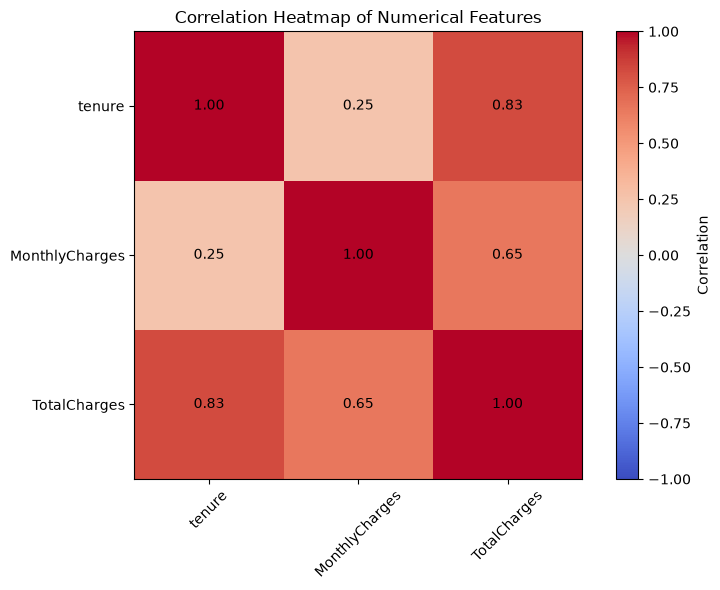


Pair plot skipped because Seaborn is not installed.

Average Numerical Features by Churn:
       tenure  MonthlyCharges  TotalCharges
Churn                                      
No      37.57           61.27       2555.34
Yes     17.98           74.44       1531.80

Average Monthly Charges by Contract and Churn:
Churn              No    Yes
Contract                    
Month-to-month  61.46  73.02
One year        62.51  85.05
Two year        60.01  86.78


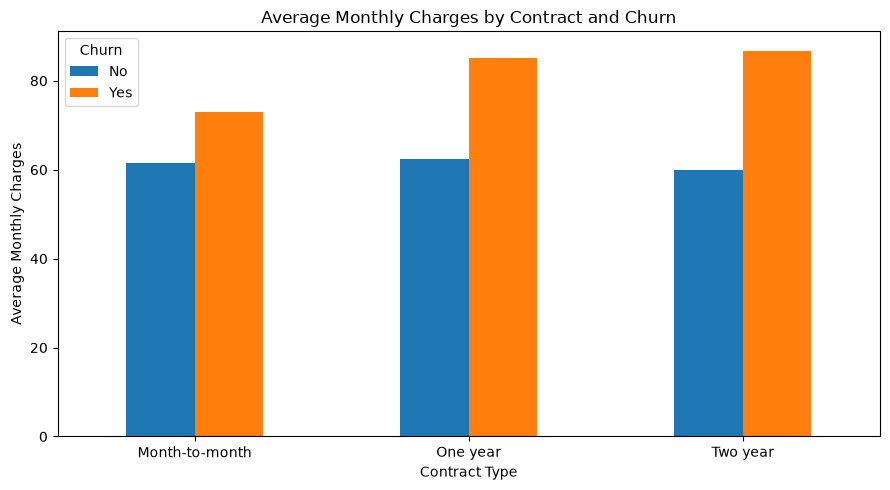


Potential Multicollinearity:
tenure and TotalCharges have a high correlation of 0.83.

Multivariate Analysis Completed.
Features analyzed: ['tenure', 'MonthlyCharges', 'TotalCharges']
Target variable: Churn
Categorical interaction feature: Contract
Review the correlation matrix, heatmap, pair plot,
group summaries, and interaction plot to identify patterns.


In [1]:
# Step 3: Implement the Concept – Multivariate Analysis

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

try:
    import seaborn as sns
except ImportError:
    sns = None

# Load the dataset
file_path = Path("dataset/Telco-Customer-Churn.csv")

df = pd.read_csv(file_path)

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Select numerical features
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Remove rows with missing values in selected numerical features
numeric_df = df[numerical_features].dropna()

print("Dataset shape:", df.shape)
print("\nNumerical features:", numerical_features)


# 1. Correlation Matrix
correlation_matrix = numeric_df.corr()

print("\nCorrelation Matrix:")
print(correlation_matrix.round(2))


# 2. Identify Strong, Weak, and Negative Correlations
print("\nCorrelation Analysis:")

for i in range(len(numerical_features)):
    for j in range(i + 1, len(numerical_features)):

        feature_1 = numerical_features[i]
        feature_2 = numerical_features[j]

        correlation = correlation_matrix.loc[
            feature_1, feature_2
        ]

        if abs(correlation) >= 0.70:
            strength = "Strong"
        elif abs(correlation) >= 0.30:
            strength = "Moderate"
        else:
            strength = "Weak"

        if correlation > 0:
            direction = "Positive"
        elif correlation < 0:
            direction = "Negative"
        else:
            direction = "No linear direction"

        print(
            f"{feature_1} vs {feature_2}: "
            f"{correlation:.2f} - {strength} {direction} correlation"
        )


# 3. Correlation Heatmap
if sns is not None:
    plt.figure(figsize=(8, 6))

    sns.heatmap(
        correlation_matrix,
        annot=True,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        fmt=".2f"
    )

    plt.title("Correlation Heatmap of Numerical Features")
    plt.tight_layout()
    plt.show()

else:
    print("\nSeaborn is not installed. Showing a correlation matrix plot.")

    plt.figure(figsize=(8, 6))

    plt.imshow(
        correlation_matrix,
        cmap="coolwarm",
        vmin=-1,
        vmax=1
    )

    plt.colorbar(label="Correlation")

    plt.xticks(
        range(len(numerical_features)),
        numerical_features,
        rotation=45
    )

    plt.yticks(
        range(len(numerical_features)),
        numerical_features
    )

    for i in range(len(numerical_features)):
        for j in range(len(numerical_features)):
            plt.text(
                j,
                i,
                f"{correlation_matrix.iloc[i, j]:.2f}",
                ha="center",
                va="center"
            )

    plt.title("Correlation Heatmap of Numerical Features")
    plt.tight_layout()
    plt.show()


# 4. Pair Plot
if sns is not None:
    pair_df = df[
        numerical_features + ["Churn"]
    ].dropna()

    # Limit the number of rows to keep the pair plot readable
    pair_df = pair_df.sample(
        n=min(1000, len(pair_df)),
        random_state=42
    )

    sns.pairplot(
        pair_df,
        vars=numerical_features,
        hue="Churn",
        diag_kind="hist",
        corner=True
    )

    plt.suptitle(
        "Pair Plot of Numerical Features by Churn",
        y=1.02
    )

    plt.show()

else:
    print(
        "\nPair plot skipped because Seaborn is not installed."
    )


# 5. Multiple Feature Relationships
print("\nAverage Numerical Features by Churn:")

churn_summary = df.groupby("Churn")[
    numerical_features
].mean()

print(churn_summary.round(2))


# 6. Feature Interaction: MonthlyCharges and Contract Type
print("\nAverage Monthly Charges by Contract and Churn:")

interaction_summary = df.pivot_table(
    index="Contract",
    columns="Churn",
    values="MonthlyCharges",
    aggfunc="mean"
)

print(interaction_summary.round(2))


# Visualize the feature interaction
interaction_summary.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Average Monthly Charges by Contract and Churn")
plt.xlabel("Contract Type")
plt.ylabel("Average Monthly Charges")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()


# 7. Potential Multicollinearity
print("\nPotential Multicollinearity:")

found_high_correlation = False

for i in range(len(numerical_features)):
    for j in range(i + 1, len(numerical_features)):

        feature_1 = numerical_features[i]
        feature_2 = numerical_features[j]

        correlation = correlation_matrix.loc[
            feature_1, feature_2
        ]

        if abs(correlation) >= 0.80:
            print(
                f"{feature_1} and {feature_2} have a high "
                f"correlation of {correlation:.2f}."
            )

            found_high_correlation = True

if not found_high_correlation:
    print(
        "No numerical feature pair crossed the chosen "
        "0.80 correlation threshold."
    )


# 8. Final Summary
print("\nMultivariate Analysis Completed.")
print("Features analyzed:", numerical_features)
print("Target variable: Churn")
print("Categorical interaction feature: Contract")
print("Review the correlation matrix, heatmap, pair plot,")
print("group summaries, and interaction plot to identify patterns.")